In [15]:
import pickle
import sys
import pandas as pd
import anndata as ad
sys.path.append('/home/jwinchel/Heimdall/')

from Heimdall.utils import convert_to_ensembl_ids
# load transcript data
tx_df = pd.read_csv('/compute/oven-0-13/jwinchel/Lung5_Rep1/Lung5_Rep1-Flat_files_and_images/Lung5_Rep1_tx_file.csv')

# Unpickling (loading from a file)
with open('/home/jwinchel/Syndri/nsclc_playground/gene_mapping.pickle', 'rb') as f:
    gene_mapping = pickle.load(f)


tx_df['gene_id_ensembl'] = tx_df['target'].map(gene_mapping.mapping_full)
tx_df['gene_id_ensembl'] = tx_df['gene_id_ensembl'].apply(lambda x: x[0] if isinstance(x,list) else x)
cell_df = pd.read_csv('/compute/oven-0-13/jwinchel/Lung5_Rep1/Lung5_Rep1-Flat_files_and_images/Lung5_Rep1_metadata_file.csv')
st_data = ad.read_h5ad('/compute/oven-0-13/jwinchel/processed_adata/ST_NSCLC_labeltransfer_consolidated_withprobs.h5ad')
l5r1_metadata = pd.read_csv('/compute/oven-0-13/jwinchel/Lung5_Rep1/Lung5_Rep1-Flat_files_and_images/Lung5_Rep1_metadata_file.csv')

st_data = st_data[st_data.obs['Run_Tissue_name']=='Lung5_Rep1']
st_data.obs = st_data.obs.merge(l5r1_metadata[['fov','cell_ID','CenterX_local_px',
       'CenterY_local_px', 'CenterX_global_px', 'CenterY_global_px']],on=['fov','cell_ID'])
st_data.obs['cell_type'] = st_data.obs['cell_type'].astype(str)
st_data.obs.loc[st_data.obs['cell_type'].str.startswith('tumor'),'cell_type'] = 'tumor'

# load a single fov
# tx_df = tx_df[tx_df['fov'] == 26].reset_index(drop=True)
# cell_df = cell_df[cell_df['fov'] == 26].reset_index(drop=True)
cell_df.head()

,fov,cell_ID,Area,AspectRatio,CenterX_local_px,CenterY_local_px,CenterX_global_px,CenterY_global_px,Width,Height,Mean.MembraneStain,Max.MembraneStain,Mean.PanCK,Max.PanCK,Mean.CD45,Max.CD45,Mean.CD3,Max.CD3,Mean.DAPI,Max.DAPI
0,1,1,1259,1.34,1027,3631,4215.888889,158847.666667,47,35,3473,7354,715,5755,361,845,22,731,4979,26374
1,1,2,3723,1.45,2904,3618,6092.888889,158834.666667,87,60,3895,13832,18374,53158,260,1232,13,686,1110,13229
2,1,3,2010,1.62,4026,3627,7214.888889,158843.666667,68,42,2892,6048,3265,37522,378,908,19,654,10482,33824
3,1,4,3358,0.47,4230,3597,7418.888889,158813.666667,48,102,6189,16091,485,964,679,2322,5,582,6065,39512
4,1,5,1213,1.00,4258,3629,7446.888889,158845.666667,38,38,8138,19281,549,874,566,1242,17,674,3311,30136


In [18]:
from scipy import sparse
import numpy as np
def gene_cell_admix_df(
    adata,
    probs_layer="admix_probs",
    thr=0.5,
    use_nonzero_only=True,
):
    """
    Returns a long dataframe with columns:
      cell, gene, prob, is_admixed, status
    If use_nonzero_only=True, restrict to entries where X > 0 (i.e., observed transcripts).
    """
    probs = adata.layers[probs_layer]
    if sparse.issparse(probs):
        probs = probs.toarray()

    X = adata.X
    if sparse.issparse(X):
        X = X.tocsr()

    cells = np.asarray(adata.obs_names)
    genes = np.asarray(adata.var_names)

    if use_nonzero_only:
        if not sparse.issparse(adata.X):
            nz = np.nonzero(X)
            r, c = nz
        else:
            r, c = X.nonzero()

        df = pd.DataFrame({
            "cell": adata.obs['cell_ID'].values[r],
            "fov": adata.obs['fov'].values[r],
            "gene": genes[c],
            "prob": probs[r, c],
            "cell_type": adata.obs['cell_type'].values[r],
        })
    else:
        # WARNING: can be huge (n_cells * n_genes)
        r, c = np.indices(probs.shape)
        df = pd.DataFrame({
            "cell": cells[r.ravel()],
            "gene": genes[c.ravel()],
            "prob": probs.ravel(),
        })

    df["is_admixed"] = df["prob"] > thr
    df["status"] = np.where(df["is_admixed"], "admixed", "kept")
    return df

gene_cell_df = gene_cell_admix_df(st_data, probs_layer="admix_probs", thr=0.674, use_nonzero_only=True)

In [19]:
tx_df

,fov,cell_ID,x_global_px,y_global_px,x_local_px,y_local_px,z,target,CellComp,gene_id_ensembl
0,1,0,6757.401589,158836.404167,3568.512700,3619.737500,11,NEAT1,0,ENSG00000245532
1,1,0,5111.388989,156060.200067,1922.500100,843.533400,11,NEAT1,0,ENSG00000245532
2,1,0,7860.460889,157809.338167,4671.572000,2592.671500,11,CCR2,0,ENSG00000121807
3,1,0,3790.488929,155553.883467,601.600040,337.216800,11,HLA-DRA,0,ENSG00000204287
4,1,0,3290.638889,158023.641667,101.750000,2806.975000,11,HLA-DRA,Membrane,ENSG00000204287
...,...,...,...,...,...,...,...,...,...,...
37226605,30,4760,25902.627814,173480.783610,824.850037,14.116943,7,TPSAB1,Cytoplasm,ENSG00000172236
37226606,30,4760,25924.052741,173477.766764,846.274963,11.100098,1,HSP90AB1,Cytoplasm,ENSG00000096384
37226607,30,4760,25925.769416,173478.008219,847.991638,11.341553,6,GLUL,Cytoplasm,ENSG00000135821
37226608,30,4760,25914.415290,173478.941813,836.637512,12.275146,6,ADGRE2,Cytoplasm,ENSG00000127507


In [20]:
tx_df = tx_df.merge(gene_cell_df, left_on=['fov','cell_ID','gene_id_ensembl'], right_on=['fov','cell','gene'], how='left')

In [21]:
tx_df = tx_df.merge(cell_df[['fov','cell_ID','CenterX_global_px','CenterY_global_px','Width','Height']], left_on=['fov','cell_ID'], right_on=['fov','cell_ID'], how='left')

In [22]:
tx_df["dx"] = tx_df["x_global_px"] - tx_df["CenterX_global_px"]
tx_df["dy"] = tx_df["y_global_px"] - tx_df["CenterY_global_px"]

tx_df["a"] = tx_df["Width"] / 2
tx_df["b"] = tx_df["Height"] / 2

tx_df["r_norm"] = np.sqrt(
    (tx_df["dx"] / tx_df["a"])**2 +
    (tx_df["dy"] / tx_df["b"])**2
)

In [7]:
rad_prob_df = tx_df.dropna().groupby(['cell_type','fov','cell_ID','status'])[['prob','r_norm']].mean()

In [23]:
tx_df['is_admixed'].unique()

array([nan, True, False], dtype=object)

In [29]:
import numpy as np
import pandas as pd

bins = np.linspace(0, 1, 15)

tx_df["radial_bin"] = pd.cut(tx_df["r_norm"], bins=bins, include_lowest=True)

enrichment = (
    tx_df
    .groupby(['cell_type',"radial_bin"])
    .agg(
        frac_admixed=("is_admixed", "mean"),
        count=("is_admixed", "size")
    )
    .reset_index()
)

# compute bin centers
bin_centers = []
for interval in enrichment["radial_bin"]:
    bin_centers.append((interval.left + interval.right) / 2)

enrichment["bin_center"] = bin_centers

/tmp/ipykernel_571145/1359954210.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(['cell_type',"radial_bin"])


In [30]:
enrichment.dropna()

,cell_type,radial_bin,frac_admixed,count,bin_center
0,B-cell,"(-0.001, 0.0714]",0.032094,15174,0.0352
1,B-cell,"(0.0714, 0.143]",0.033293,44994,0.1072
2,B-cell,"(0.143, 0.214]",0.03263,73184,0.1785
3,B-cell,"(0.214, 0.286]",0.033091,99362,0.2500
4,B-cell,"(0.286, 0.357]",0.031411,123779,0.3215
...,...,...,...,...,...
205,tumor,"(0.643, 0.714]",0.066313,912376,0.6785
206,tumor,"(0.714, 0.786]",0.066118,892655,0.7500
207,tumor,"(0.786, 0.857]",0.066975,831351,0.8215
208,tumor,"(0.857, 0.929]",0.068228,723989,0.8930


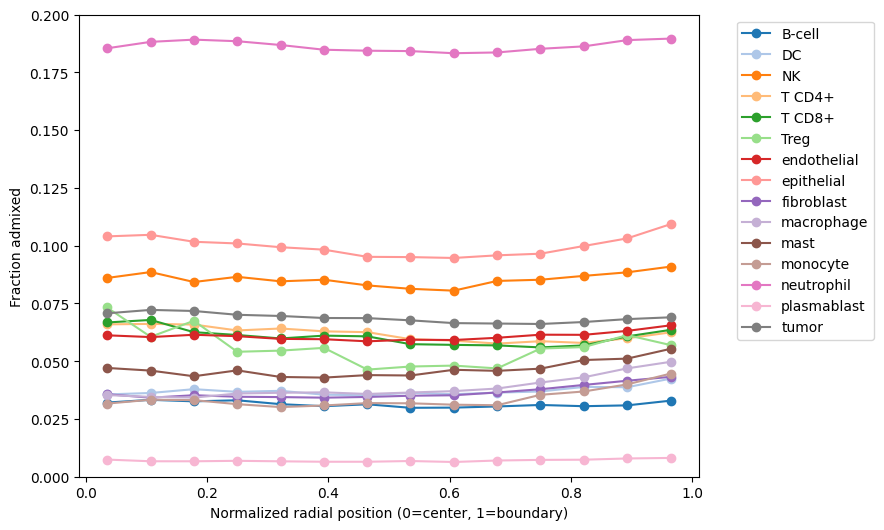

In [42]:
import matplotlib.pyplot as plt
cmap = plt.get_cmap('tab20')
ct_colors = {ct: cmap(i) for i, ct in enumerate(enrichment['cell_type'].unique())}
fig,ax = plt.subplots(figsize=(8,6))
for cell_type in enrichment['cell_type'].unique():
    subset = enrichment[(enrichment['cell_type'] == cell_type)]
    ax.plot(subset["bin_center"], subset["frac_admixed"], marker="o", label=cell_type,color=ct_colors[cell_type])

ax.set_xlabel("Normalized radial position (0=center, 1=boundary)")
ax.set_ylabel("Fraction admixed")
ax.set_ylim(0, 0.2)
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')